In [1]:
import sys
print(sys.executable)
!c:\Users\louis\anaconda3\envs\mlclass\python.exe -m pip install seaborn imbalanced-learn
%pip install scikit-learn
%pip install seaborn imbalanced-learn

C:\Users\jack\anaconda3\python.exe


The system cannot find the path specified.


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


# Data Cleansing

In [2]:
# Making sure all columns show
import pandas as pd, numpy as np
from sklearn.svm import SVC
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE

from scipy.stats import pearsonr

df = pd.read_csv("adult.csv")

print(df.shape)
df.info()
df.describe(include='all')

(32561, 15)
<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 6.2 MB


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
count,32561.000000,32561,3.256100e+04,32561,32561.000000,32561,32561,32561,32561,32561,32561.000000,32561.000000,32561.000000,32561,32561
unique,NaN,9,NaN,16,NaN,7,15,6,5,2,NaN,NaN,NaN,42,2
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,22696,NaN,10501,NaN,14976,4140,13193,27816,21790,NaN,NaN,NaN,29170,24720
mean,38.581647,NaN,1.897784e+05,NaN,10.080679,NaN,NaN,NaN,NaN,NaN,1077.648844,87.303830,40.437456,NaN,NaN
std,13.640433,NaN,1.055500e+05,NaN,2.572720,NaN,NaN,NaN,NaN,NaN,7385.292085,402.960219,12.347429,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.178270e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.783560e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.370510e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


In [3]:
# For some reason this dataset has missing values as ?, so we're replacing them with NAN.
df = df.replace("?", np.nan)
# strip whitespace from all text columns
for c in df.select_dtypes(include=['object', 'str']).columns:
    df[c] = df[c].str.strip()

In [4]:
# Drop all missing values
df = df.dropna()

In [5]:
# Remove duplicates
df = df.drop_duplicates()

In [6]:
# Dropping Education since education.num is essentially an encoded numeric representation that's easier to work with. Here is the matching:
'''
Preschool	1
1st-4th	2
5th-6th	3
7th-8th	4
9th	5
10th	6
11th	7
12th	8
HS-grad	9
Some-college	10
Assoc-voc	11
Assoc-acdm	12
Bachelors	13
Masters	14
Prof-school	15
Doctorate	16
'''
# Also dropping fnlwgt since its just a sampling weight. Additionally dropping capital gain/loss.
df = df.drop(columns=['education', 'fnlwgt', 'capital.gain', 'capital.loss'])

In [7]:
# Encoding income to be binary, 0 if less than 50k, 1 if more.
df['income'] = df['income'].map({'<=50K': 0, '>50K': 1})

In [8]:
# Turning native country into either US or Other, since its 90% U.S
df['native.country'] = np.where(df['native.country']=='United-States', 'US', 'Other')

In [9]:
# Turning all the string values into binary values (one hot encoding)

df_raw = df.copy() # making a copy for later

df = pd.get_dummies(df, columns=['workclass','marital.status','occupation',
                                 'relationship','race','sex','native.country'],
                    drop_first=True)


In [10]:
print(*(f"{col}: {dtype}" for col, dtype in zip(df.columns, df.dtypes)), sep="\n")

age: int64
education.num: int64
hours.per.week: int64
income: int64
workclass_Local-gov: bool
workclass_Private: bool
workclass_Self-emp-inc: bool
workclass_Self-emp-not-inc: bool
workclass_State-gov: bool
workclass_Without-pay: bool
marital.status_Married-AF-spouse: bool
marital.status_Married-civ-spouse: bool
marital.status_Married-spouse-absent: bool
marital.status_Never-married: bool
marital.status_Separated: bool
marital.status_Widowed: bool
occupation_Armed-Forces: bool
occupation_Craft-repair: bool
occupation_Exec-managerial: bool
occupation_Farming-fishing: bool
occupation_Handlers-cleaners: bool
occupation_Machine-op-inspct: bool
occupation_Other-service: bool
occupation_Priv-house-serv: bool
occupation_Prof-specialty: bool
occupation_Protective-serv: bool
occupation_Sales: bool
occupation_Tech-support: bool
occupation_Transport-moving: bool
relationship_Not-in-family: bool
relationship_Other-relative: bool
relationship_Own-child: bool
relationship_Unmarried: bool
relationship

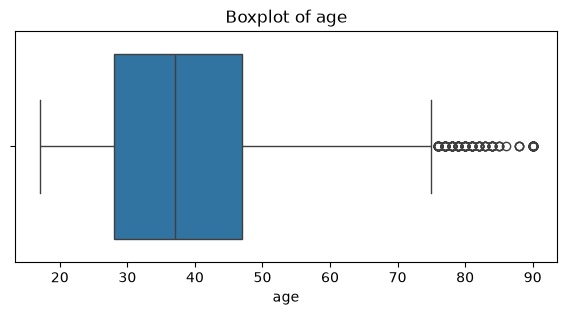

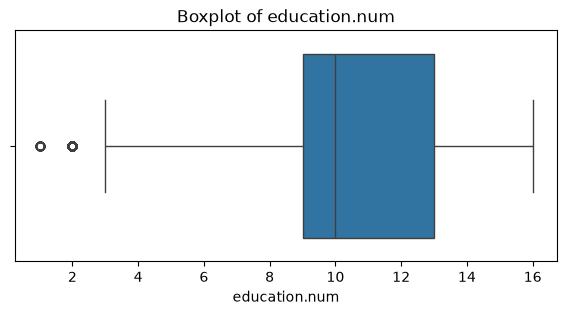

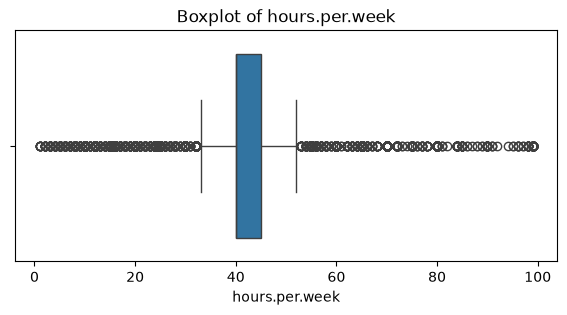

In [11]:
# Check for Outliers using boxplots
numerical_cols = df.select_dtypes(
    include=['int64', 'float64']
).columns.drop('income', errors='ignore')

for col in numerical_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [12]:
# Check for Outliers numerically
outlier_results = []

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        'Column': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage': round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

outlier_summary

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,28.0,47.0,19.0,-0.5,75.5,168,0.56
1,education.num,9.0,13.0,4.0,3.0,19.0,193,0.64
2,hours.per.week,40.0,45.0,5.0,32.5,52.5,7947,26.37


In [13]:
# Investigate outliers. Age and education.num outliers are realistic and not IMPOSSIBLE. Will check hours per week if anything exceeds 168
invalid_hours = df[df['hours.per.week'] > 168]
print("Invalid records:", len(invalid_hours))

Invalid records: 0


### Feature Engineering

In [14]:
# Creating Age Brackets and education brackets
bins = [0, 0.2, 0.4, 0.6, 1.0]
labels = ['very_young', 'young', 'middle_aged', 'old']

df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels, right=False)
df = pd.get_dummies(df, columns=['age_group'],
                    drop_first=True)

# Education category identifies based off of degree earned: None, highschool-associates, bachelors, masters, doctorate
bins = [0, 8, 12, 13, 14, 16]
labels = ['no_degree', 'low_degree', 'bachelors', 'masters', 'doctorate']
df['education_category'] = pd.cut(df['education.num'], bins=bins, labels=labels, right=False)
df = pd.get_dummies(df, columns=['education_category'],
                    drop_first=True)

# education.num x hours.per.week
df['education.by.hours.worked'] = df['education.num'] * df['hours.per.week']
print(df['education.by.hours.worked'].max())
df['education.by.hours.worked'] = df['education.by.hours.worked'] / 1584
df.head()

1584


,age,education.num,hours.per.week,income,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,...,sex_Male,native.country_US,age_group_young,age_group_middle_aged,age_group_old,education_category_low_degree,education_category_bachelors,education_category_masters,education_category_doctorate,education.by.hours.worked
1,82,9,18,0,False,True,False,False,False,False,...,False,True,False,False,False,True,False,False,False,0.102273
3,54,4,40,0,False,True,False,False,False,False,...,False,True,False,False,False,False,False,False,False,0.101010
4,41,10,40,0,False,True,False,False,False,False,...,False,True,False,False,False,True,False,False,False,0.252525
5,34,9,45,0,False,True,False,False,False,False,...,False,True,False,False,False,True,False,False,False,0.255682
6,38,6,40,0,False,True,False,False,False,False,...,True,True,False,False,False,False,False,False,False,0.151515


In [15]:
# Split dataset for training into 80/20 data,
from sklearn.model_selection import train_test_split
X = df.drop(columns=['income'])
y = df['income']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Scale numeric features and fit the scaler on the training data
from sklearn.preprocessing import StandardScaler
num_cols = ['age','education.num', 'hours.per.week']

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols]  = scaler.transform(X_test[num_cols])

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train, y_train
)

# Check class distribution
print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
income
0    18106
1     6005
Name: count, dtype: int64

After SMOTE:
income
0    18106
1    18106
Name: count, dtype: int64


In [16]:
# Just making sure everything is good
print(X_train.isna().sum().sum(), "missing in train") 
print(X_train.dtypes.value_counts())
print(X_train.shape, X_test.shape)

0 missing in train
bool       43
float64     4
Name: count, dtype: int64
(24111, 47) (6028, 47)


# Analysis
Here we will analyze the data to gather relevant statistics.


In [17]:
analysis_Y = df_raw["income"].astype(int) 
analysis_X = df_raw.drop(columns=["income"])

## Check for Class Imbalance

In [18]:
print(analysis_Y.value_counts(normalize=True).round(3))

income
0    0.751
1    0.249
Name: proportion, dtype: float64


## Target distribution
Show class imabalance visually

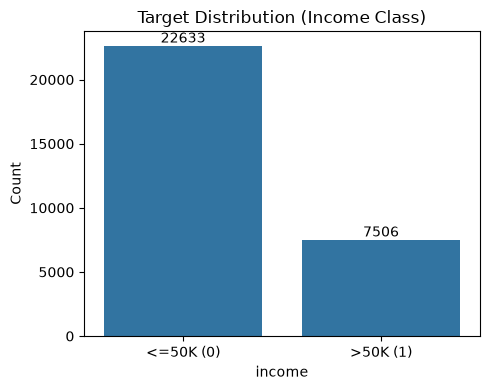

income
0    0.751
1    0.249
Name: proportion, dtype: float64


In [19]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(x=df_raw['income'])
ax.set_xticks([0, 1]); ax.set_xticklabels(['<=50K (0)', '>50K (1)'])
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.title('Target Distribution (Income Class)'); plt.ylabel('Count')
plt.tight_layout(); plt.show()

print(df_raw['income'].value_counts(normalize=True).round(3))

### Income rate by categorical features

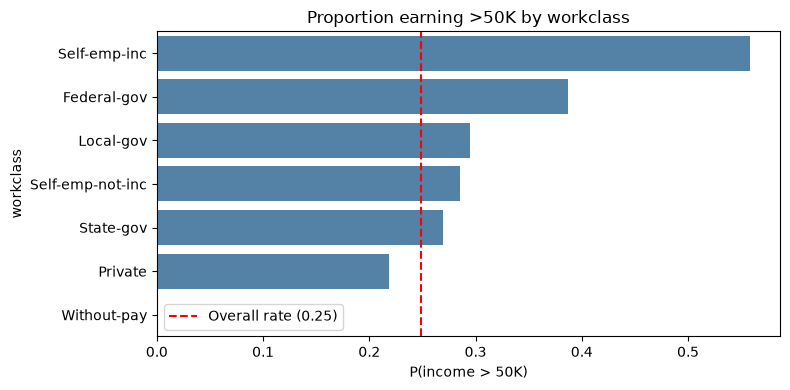

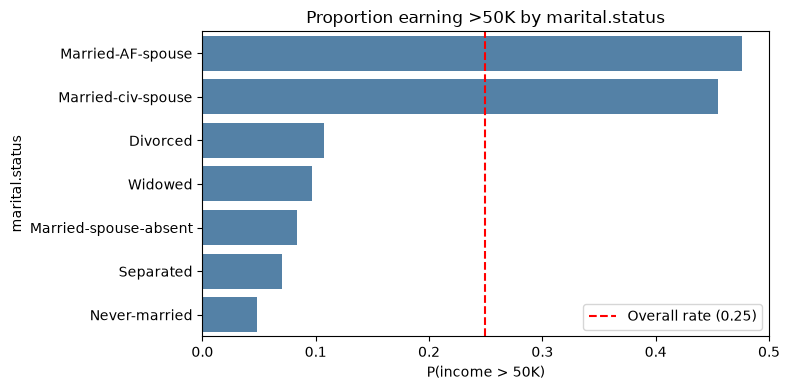

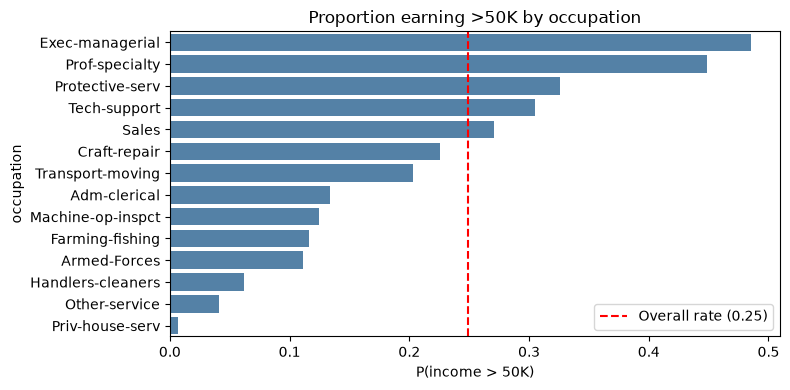

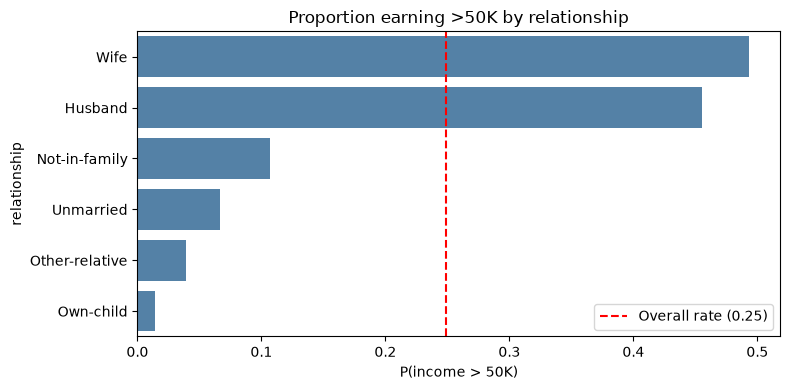

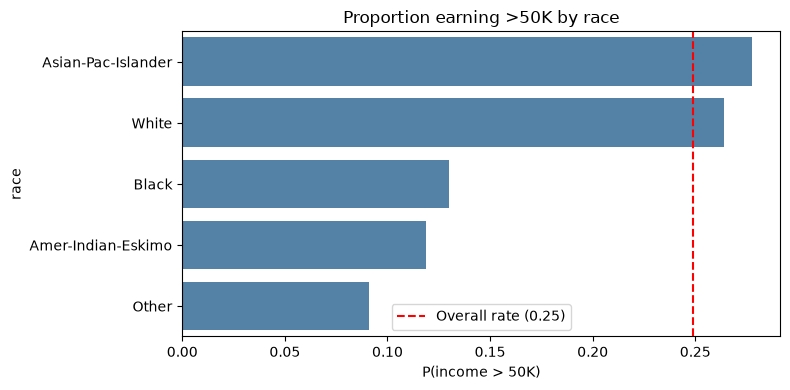

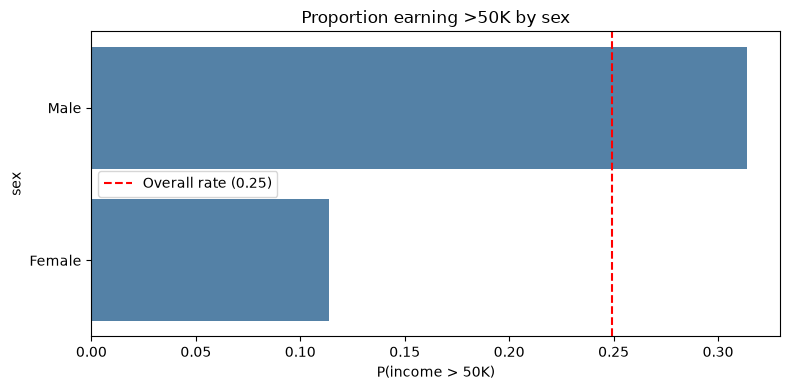

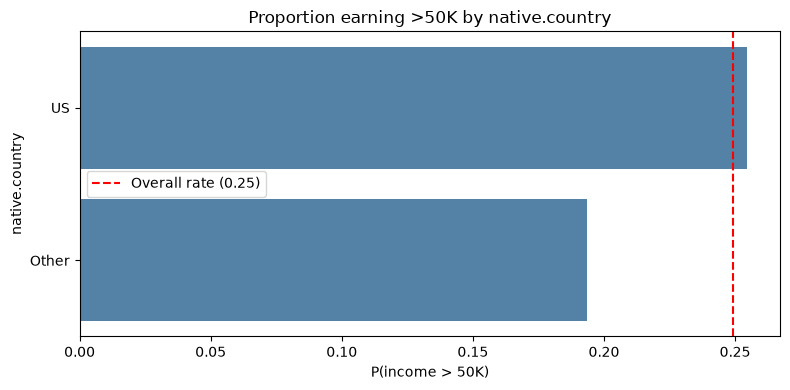

In [20]:
cat_features = ['workclass','marital.status','occupation',
                'relationship','race','sex','native.country']
overall = df_raw['income'].mean()

for col in cat_features:
    rate = df_raw.groupby(col)['income'].mean().sort_values(ascending=False)
    plt.figure(figsize=(8, 4))
    sns.barplot(x=rate.values, y=rate.index, color='steelblue')
    plt.axvline(overall, color='red', linestyle='--', label=f'Overall rate ({overall:.2f})')
    plt.title(f'Proportion earning >50K by {col}')
    plt.xlabel('P(income > 50K)'); plt.ylabel(col); plt.legend()
    plt.tight_layout(); plt.show()

### Income rate by education level

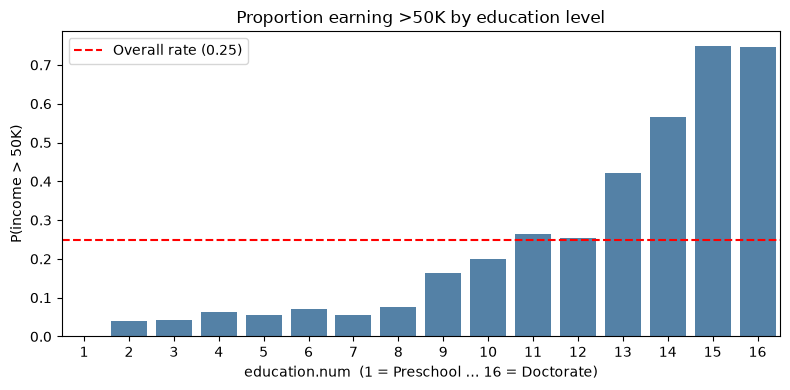

In [21]:
plt.figure(figsize=(8, 4))
edu_rate = df_raw.groupby('education.num')['income'].mean()
sns.barplot(x=edu_rate.index, y=edu_rate.values, color='steelblue')
plt.axhline(overall, color='red', linestyle='--', label=f'Overall rate ({overall:.2f})')
plt.title('Proportion earning >50K by education level')
plt.xlabel('education.num  (1 = Preschool … 16 = Doctorate)')
plt.ylabel('P(income > 50K)'); plt.legend()
plt.tight_layout(); plt.show()

### Numeric correlation heatmap

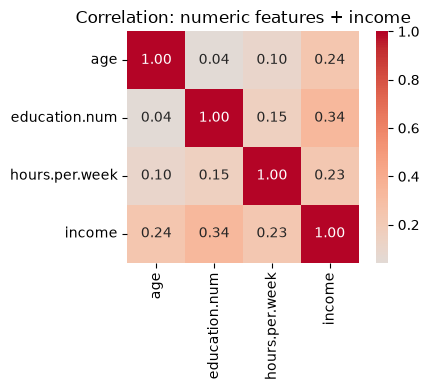

In [22]:
plt.figure(figsize=(5, 4))
corr = df_raw[['age', 'education.num', 'hours.per.week', 'income']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f', square=True)
plt.title('Correlation: numeric features + income')
plt.tight_layout(); plt.show()

### Numeric features by income boxplots

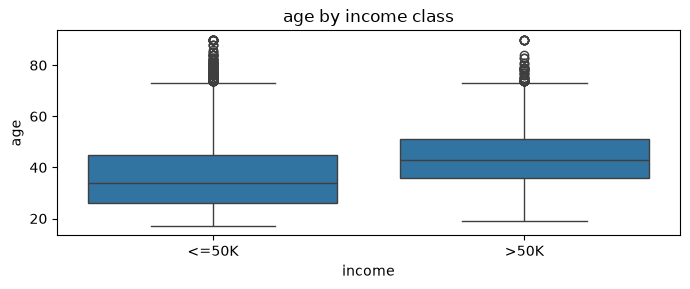

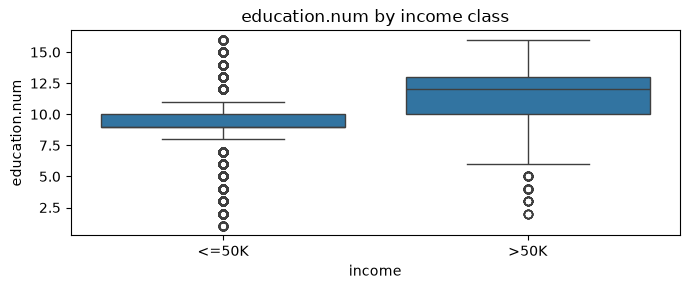

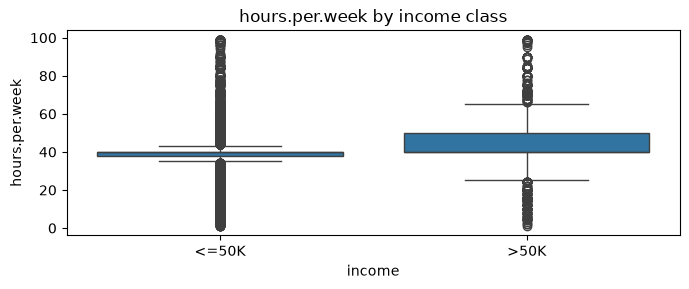

In [23]:
for col in ['age', 'education.num', 'hours.per.week']:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x='income', y=col, data=df_raw)
    plt.xticks([0, 1], ['<=50K', '>50K'])
    plt.title(f'{col} by income class')
    plt.tight_layout(); plt.show()

There appears to be some class imbalance, with 75% of the samples falling in the earnig less than 50k category.

### Check Pearson Correlation Coef against Target 
for Numerical features

In [24]:
num_assoc = analysis_X[num_cols].corrwith(analysis_Y).sort_values(key=abs, ascending=False)
print(num_assoc.round(3))


education.num     0.335
age               0.242
hours.per.week    0.229
dtype: float64


No single feature has too high of a correlation against the target (>0.75), indicating that these features do not need to be removed for being overly correlated.

### Check Chi2 P value against Target

for Categorical features


In [25]:
from scipy.stats import chi2_contingency

rows = []
for c in num_cols:
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(analysis_X[c], analysis_Y))
    rows.append({"column": c, "chi2": chi2, "dof": dof, "p_value": p})

chi_table = pd.DataFrame(rows).sort_values("chi2", ascending=False).reset_index(drop=True)
print(chi_table.to_string(index=False))

        column        chi2  dof  p_value
 education.num 4069.280020   15      0.0
           age 3182.201477   71      0.0
hours.per.week 2404.345452   93      0.0


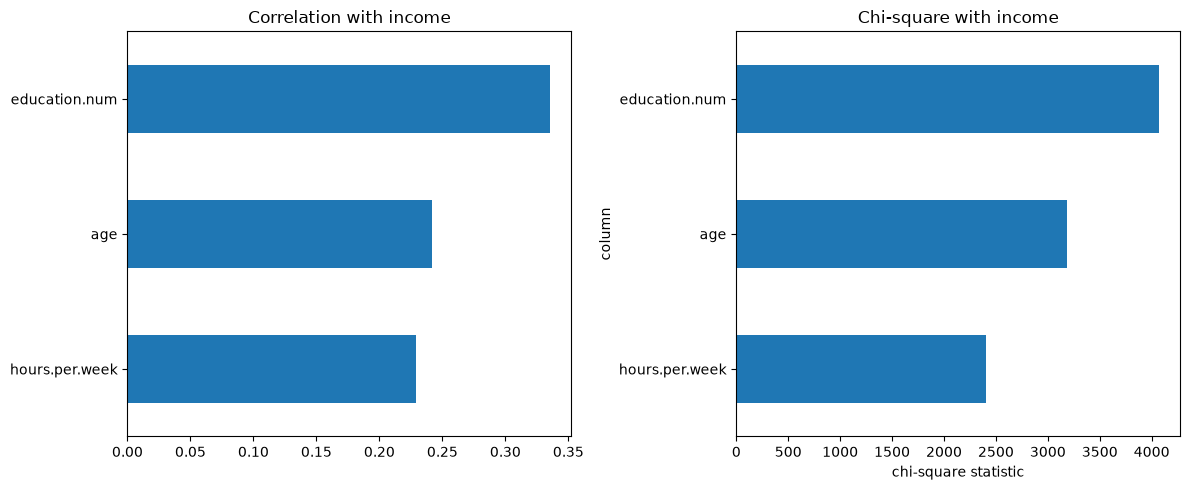

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
num_assoc.sort_values().plot(kind="barh", ax=axes[0])

axes[0].set_title("Correlation with income")
chi_table.sort_values("chi2").plot(kind="barh", x="column", y="chi2", ax=axes[1], legend=False)

axes[1].set_title("Chi-square with income")
axes[1].set_xlabel("chi-square statistic")
plt.tight_layout()
plt.show()

According to the Chi-square statistics and p-values, every categorical variable shows signs of association with the target variable, meaning that we do not need to remove it for being irrelevant.

In [27]:
for _, row in chi_table.iterrows():
    print(f"{row['column']}: is under 0.05? {row['p_value'] < 0.05}")

# Numeric columns (Pearson p-values)
for c in num_cols:
    r, p = pearsonr(analysis_X[c], analysis_Y)
    print(f"{c}: is under 0.05? {p < 0.05}")

education.num: is under 0.05? True
age: is under 0.05? True
hours.per.week: is under 0.05? True
age: is under 0.05? True
education.num: is under 0.05? True
hours.per.week: is under 0.05? True


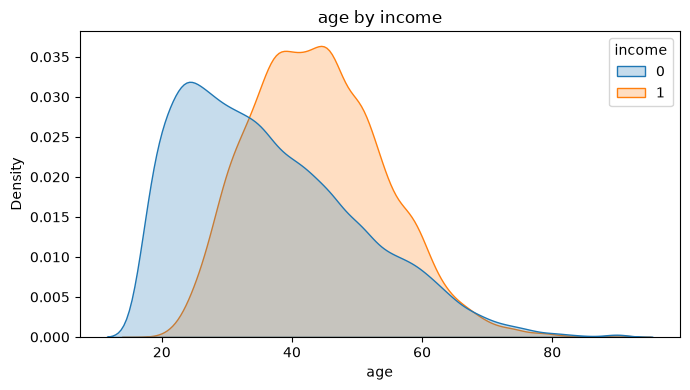

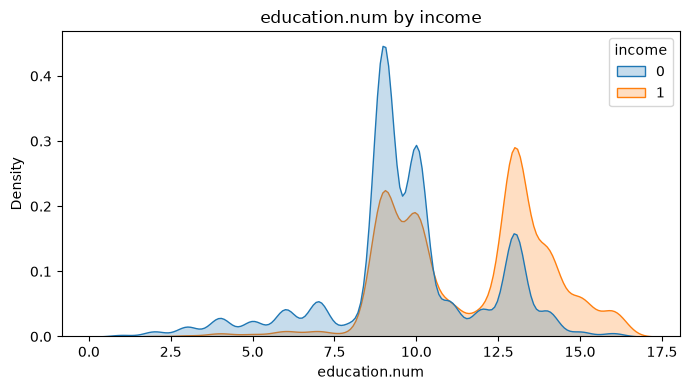

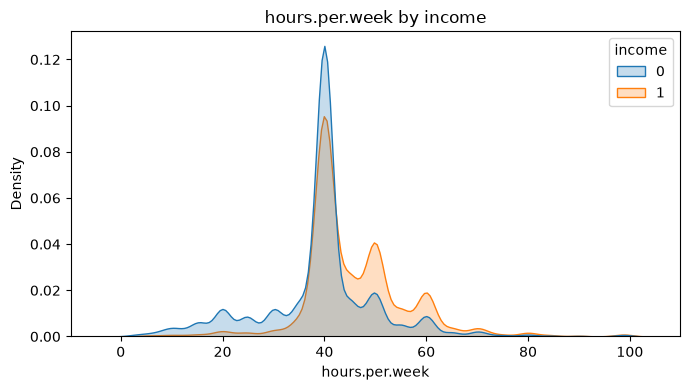

In [28]:
plot_df = analysis_X[num_cols].assign(income=analysis_Y)

for c in num_cols:
    plt.figure(figsize=(7, 4))
    sns.kdeplot(data=df_raw, x=c, hue="income", common_norm=False, fill=True)
    plt.title(f"{c} by income")
    plt.tight_layout()
    plt.show()

We plot the distributions of each numerical value for each population, to quickly glance and see if there are clear differences in distributions. This affirms that these are good features as the distributions between the two classes appear to be different, suggesting there is a correlation.

# Model 1: Ensemble Learning with Decision Trees

In [29]:
# Exploring what the data actually looks like right now
df.describe(include='all')
pd.set_option('display.max_columns', None)
df.head()

,age,education.num,hours.per.week,income,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,marital.status_Married-AF-spouse,marital.status_Married-civ-spouse,marital.status_Married-spouse-absent,marital.status_Never-married,marital.status_Separated,marital.status_Widowed,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Male,native.country_US,age_group_young,age_group_middle_aged,age_group_old,education_category_low_degree,education_category_bachelors,education_category_masters,education_category_doctorate,education.by.hours.worked
1,82,9,18,0,False,True,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,True,False,False,False,True,False,False,False,0.102273
3,54,4,40,0,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,True,False,False,False,False,False,False,False,0.101010
4,41,10,40,0,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,True,False,True,False,False,False,True,False,False,False,0.252525
5,34,9,45,0,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,True,False,False,False,True,False,False,False,0.255682
6,38,6,40,0,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,True,True,False,False,False,False,False,False,False,0.151515


In [30]:
print(df.shape[0])

30139


In [31]:
print(y_test[y_test== 1].count())

1501


In [32]:
# Looking at the distribution of classes
for col in df:
    print(df[col].value_counts(), "\n")

age
36    852
31    851
33    837
34    836
37    828
     ... 
82      7
83      5
88      3
85      3
86      1
Name: count, Length: 72, dtype: int64 

education.num
9     9834
10    6669
13    5042
14    1626
11    1307
7     1048
12    1008
6      820
4      556
15     542
5      455
8      377
16     375
3      287
2      149
1       44
Name: count, dtype: int64 

hours.per.week
40    14239
50     2716
45     1752
60     1405
35     1183
      ...  
87        1
94        1
82        1
92        1
74        1
Name: count, Length: 94, dtype: int64 

income
0    22633
1     7506
Name: count, dtype: int64 

workclass_Local-gov
False    28072
True      2067
Name: count, dtype: int64 

workclass_Private
True     22264
False     7875
Name: count, dtype: int64 

workclass_Self-emp-inc
False    29065
True      1074
Name: count, dtype: int64 

workclass_Self-emp-not-inc
False    27641
True      2498
Name: count, dtype: int64 

workclass_State-gov
False    28860
True      1279
Name: count, d

In [33]:
clf = tree.DecisionTreeClassifier()
clf.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



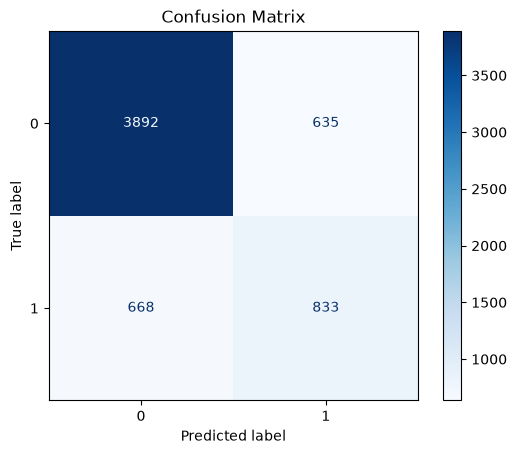

In [34]:
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap=plt.cm.Blues) 
plt.title("Confusion Matrix")
plt.show() 

In [35]:
def predict_on_subset(col, val, model):
    df_subset = df[df[col] == val]
    X_subset = df_subset.drop(columns=['income'])
    y_subset = df_subset['income']
    X_train_subset, X_test_subset, y_train_subset, y_test_subset = train_test_split(
        X_subset, y_subset, test_size=0.2, random_state=42, stratify=y_subset)
    y_pred_subset = model.predict(X_test_subset)
    cm = confusion_matrix(y_test_subset, y_pred_subset)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
    disp.plot(cmap=plt.cm.Blues) 
    print(classification_report(y_test, y_pred))
    plt.title("Confusion Matrix")
    plt.show() 


              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



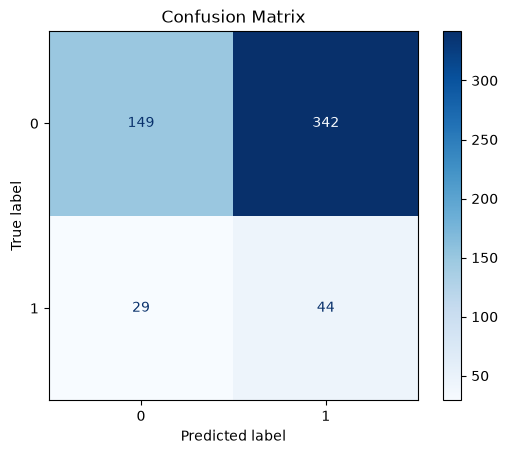

In [36]:
predict_on_subset('race_Black', True, clf)

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



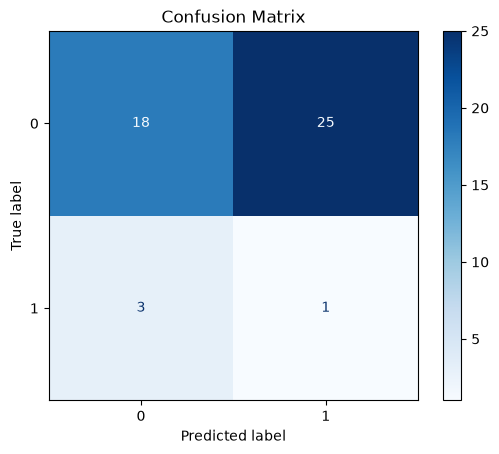

In [37]:
predict_on_subset('race_Other', True, clf)

In [38]:
def test_model(clf):
    y_pred = clf.predict(X_test)
    print(classification_report(y_test, y_pred))
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
    disp.plot(cmap=plt.cm.Blues) 
    plt.title("Confusion Matrix")
    plt.show() 

              precision    recall  f1-score   support

           0       0.85      0.85      0.85      4527
           1       0.55      0.55      0.55      1501

    accuracy                           0.78      6028
   macro avg       0.70      0.70      0.70      6028
weighted avg       0.78      0.78      0.78      6028



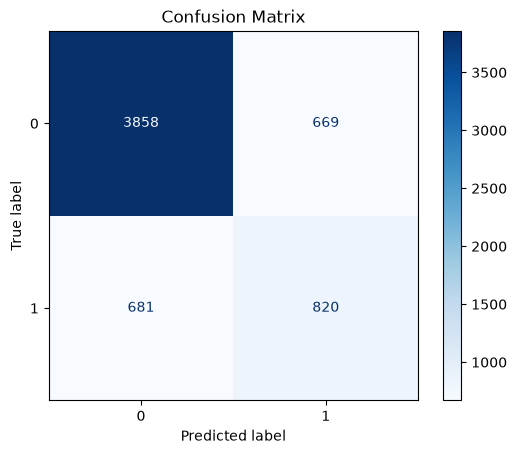

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.56      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



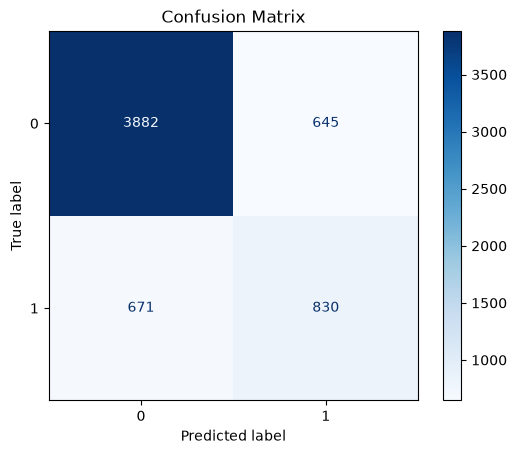

In [39]:
clf = tree.DecisionTreeClassifier(criterion='entropy')
clf.fit(X_train, y_train)
test_model(clf)
clf = tree.DecisionTreeClassifier(criterion='gini')
clf.fit(X_train, y_train)
test_model(clf)

              precision    recall  f1-score   support

           0       0.87      0.91      0.89      4527
           1       0.69      0.57      0.62      1501

    accuracy                           0.83      6028
   macro avg       0.78      0.74      0.76      6028
weighted avg       0.82      0.83      0.82      6028



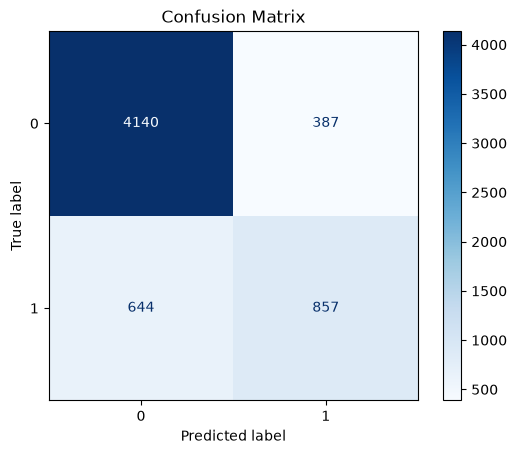

In [40]:
clf = tree.DecisionTreeClassifier(max_depth=5)
clf.fit(X_train, y_train)
test_model(clf)

              precision    recall  f1-score   support

           0       0.87      0.88      0.88      4527
           1       0.63      0.60      0.62      1501

    accuracy                           0.81      6028
   macro avg       0.75      0.74      0.75      6028
weighted avg       0.81      0.81      0.81      6028



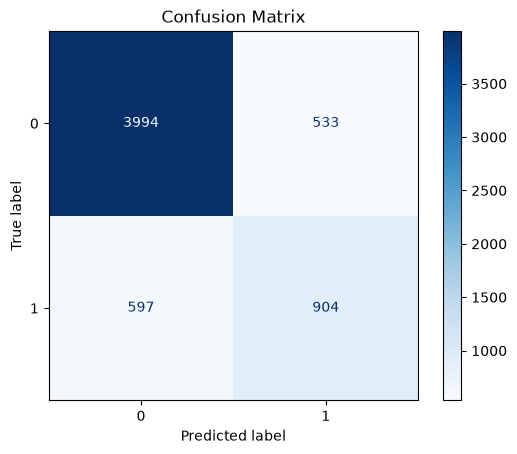

In [41]:
clf = tree.DecisionTreeClassifier(max_depth=15)
clf.fit(X_train, y_train)
test_model(clf)

              precision    recall  f1-score   support

           0       0.87      0.90      0.89      4527
           1       0.66      0.60      0.63      1501

    accuracy                           0.82      6028
   macro avg       0.77      0.75      0.76      6028
weighted avg       0.82      0.82      0.82      6028



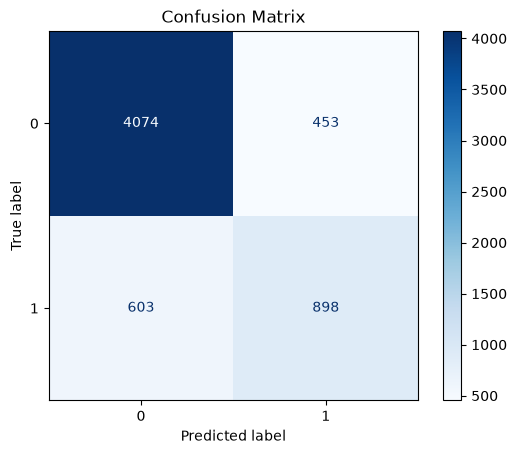

              precision    recall  f1-score   support

           0       0.86      0.87      0.87      4527
           1       0.60      0.57      0.59      1501

    accuracy                           0.80      6028
   macro avg       0.73      0.72      0.73      6028
weighted avg       0.80      0.80      0.80      6028



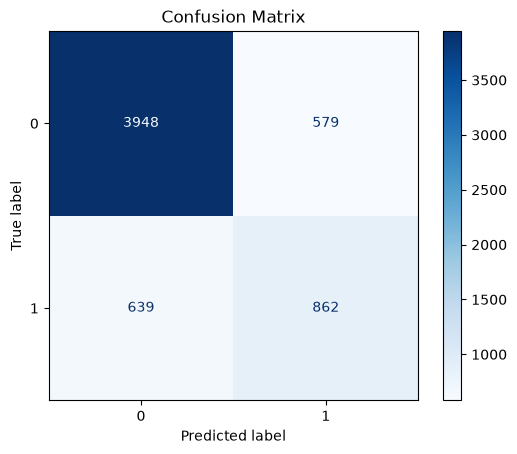

In [42]:
clf = tree.DecisionTreeClassifier(max_depth=10)
clf.fit(X_train, y_train)
test_model(clf)
clf = tree.DecisionTreeClassifier(max_depth=20)
clf.fit(X_train, y_train)
test_model(clf)

It looks like a decision tree with a maximum depth of 15 works the best with the highest f1 score and achieves the best fit for correctly identifying actual positive cases

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



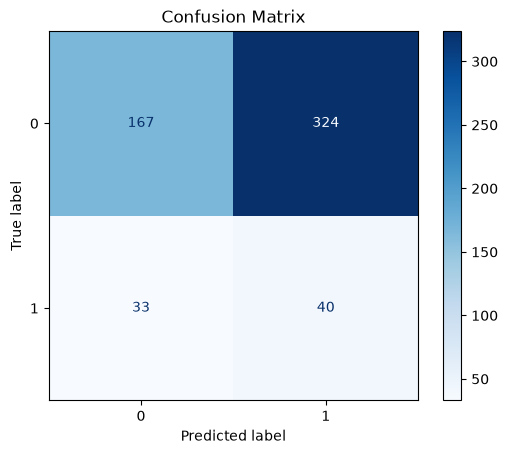

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



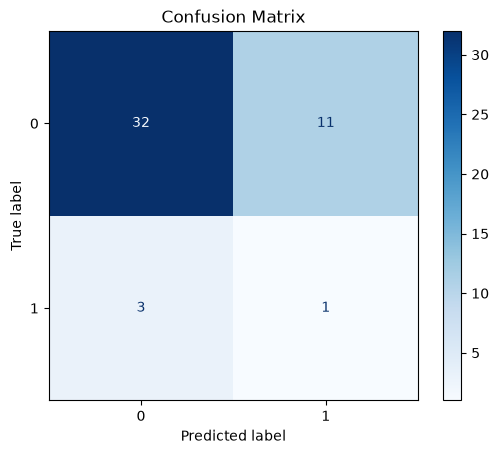

In [43]:
predict_on_subset('race_Black', True, clf)
predict_on_subset('race_Other', True, clf)

However, the limited depth is making it less prone to correctly predicting high income black earners which is problematic. I am going to try bagging next to see if it can provide a better fit

In [44]:
from sklearn.ensemble import BaggingClassifier

              precision    recall  f1-score   support

           0       0.88      0.90      0.89      4527
           1       0.68      0.62      0.65      1501

    accuracy                           0.83      6028
   macro avg       0.78      0.76      0.77      6028
weighted avg       0.83      0.83      0.83      6028



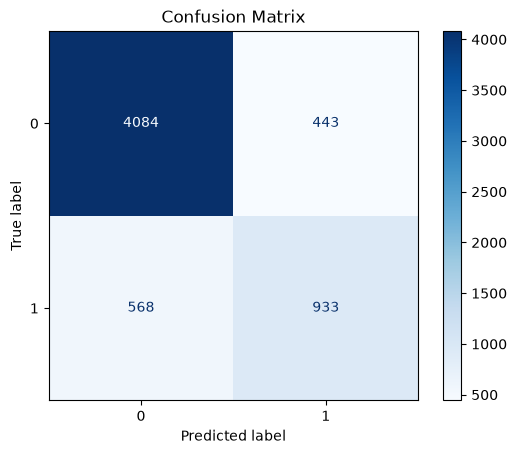

In [45]:
base_tree = tree.DecisionTreeClassifier(max_depth=15)
bagging_clf = bagging_clf = BaggingClassifier(estimator=base_tree, n_estimators=50, max_samples=0.8, bootstrap=True, random_state=42)
bagging_clf.fit(X_train, y_train)
test_model(bagging_clf)

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



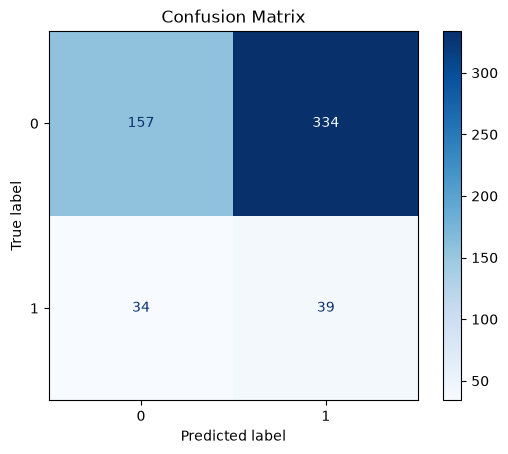

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



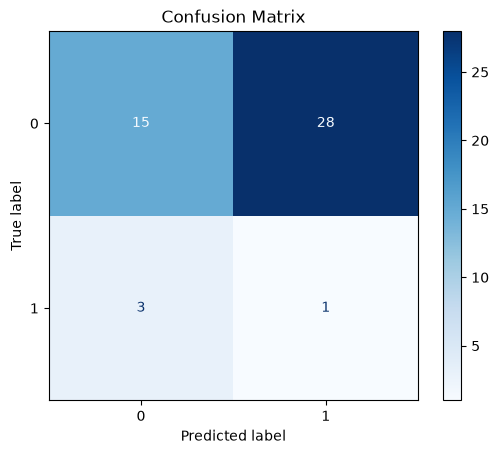

In [46]:
predict_on_subset('race_Black', True, bagging_clf)
predict_on_subset('race_Other', True, bagging_clf)

              precision    recall  f1-score   support

           0       0.87      0.89      0.88      4527
           1       0.64      0.59      0.61      1501

    accuracy                           0.81      6028
   macro avg       0.75      0.74      0.75      6028
weighted avg       0.81      0.81      0.81      6028



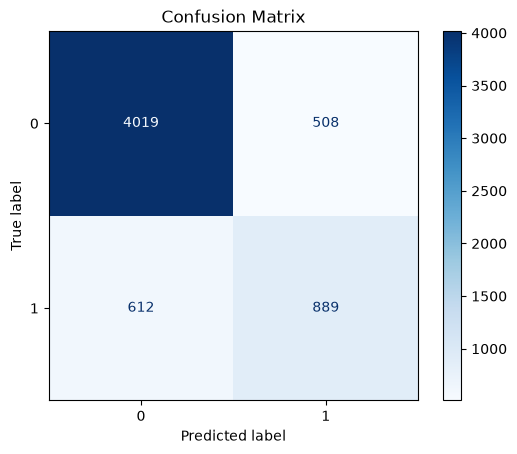

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



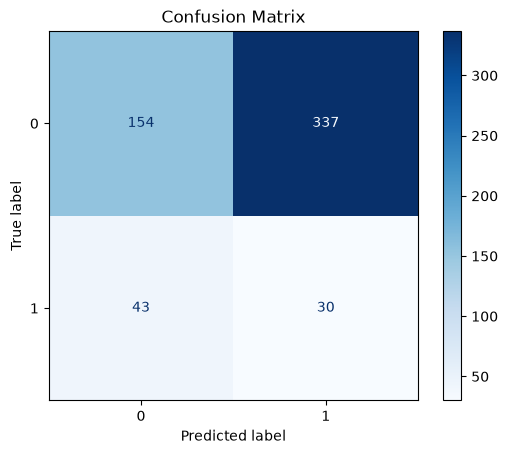

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



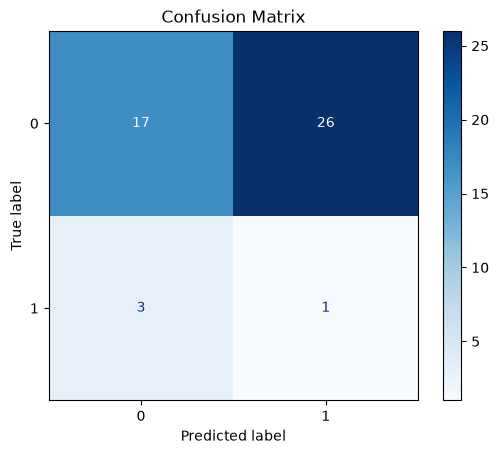

In [47]:
base_tree = tree.DecisionTreeClassifier(max_depth=50)
bagging_clf = bagging_clf = BaggingClassifier(estimator=base_tree, n_estimators=50, max_samples=0.8, bootstrap=True, random_state=42)
bagging_clf.fit(X_train, y_train)
test_model(bagging_clf)
predict_on_subset('race_Black', True, bagging_clf)
predict_on_subset('race_Other', True, bagging_clf)

### Trying with class weights balanced

              precision    recall  f1-score   support

           0       0.92      0.77      0.84      4527
           1       0.53      0.80      0.64      1501

    accuracy                           0.77      6028
   macro avg       0.73      0.78      0.74      6028
weighted avg       0.82      0.77      0.79      6028



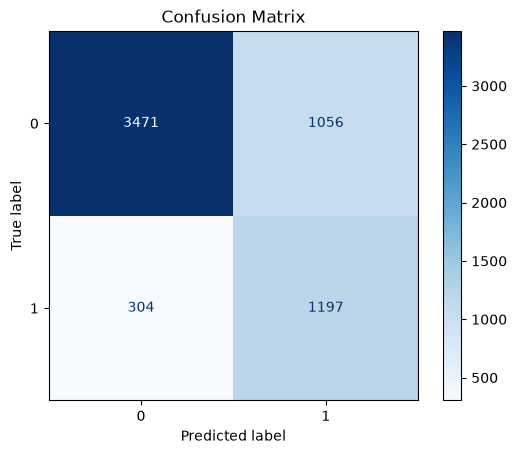

In [48]:
clf = tree.DecisionTreeClassifier(max_depth=15, class_weight='balanced')
clf.fit(X_train, y_train)
test_model(clf)

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



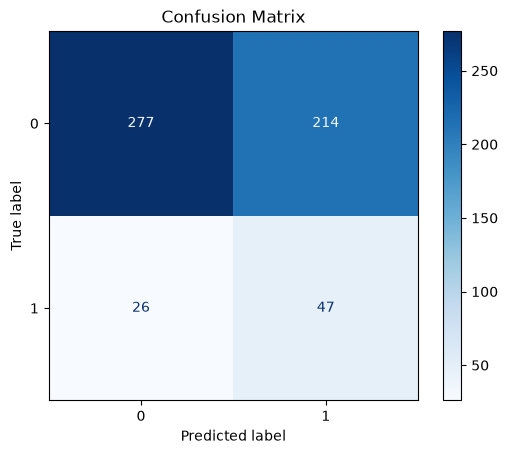

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



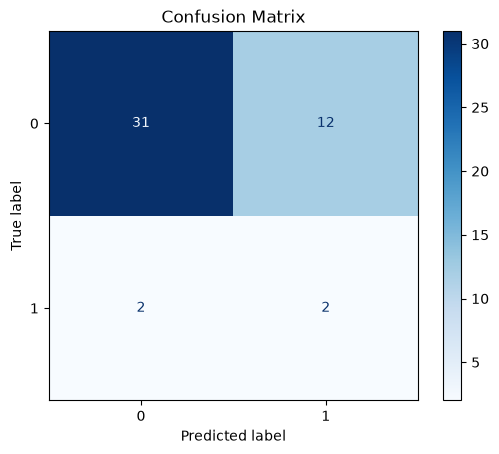

In [49]:
predict_on_subset('race_Black', True, clf)
predict_on_subset('race_Other', True, clf)

Balancing the class weights did a really good job at mitigating the racial bias within the model, but it did result in lower overall accuracy. I am going to try increasing the depth to see if that can help

              precision    recall  f1-score   support

           0       0.90      0.80      0.84      4527
           1       0.54      0.72      0.62      1501

    accuracy                           0.78      6028
   macro avg       0.72      0.76      0.73      6028
weighted avg       0.81      0.78      0.79      6028



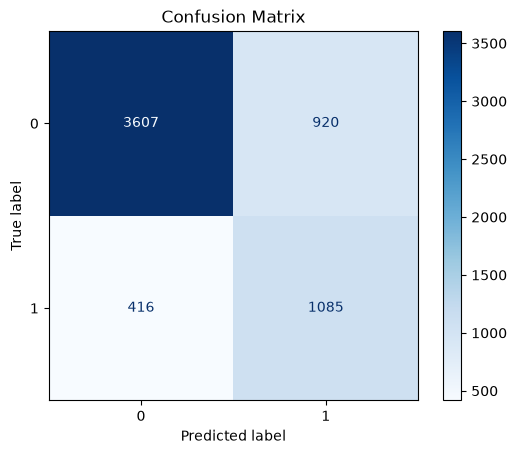

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



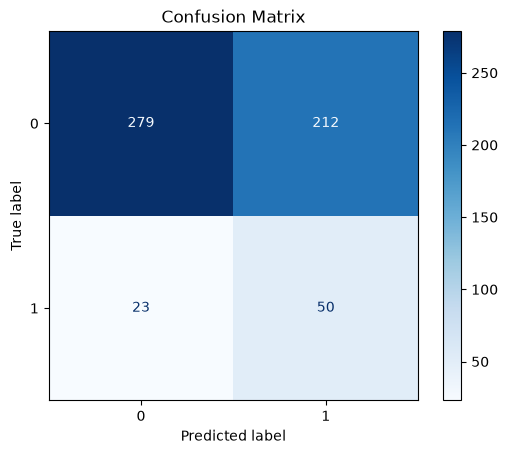

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



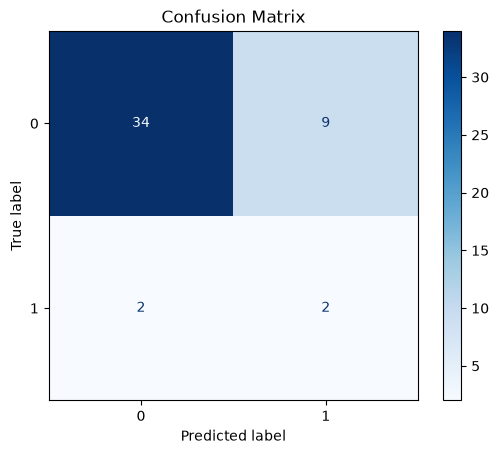

In [50]:
clf = tree.DecisionTreeClassifier(max_depth=20, class_weight='balanced')
clf.fit(X_train, y_train)
test_model(clf)
predict_on_subset('race_Black', True, clf)
predict_on_subset('race_Other', True, clf)

20 seems like a better depth now with a 0.87 F1 score compared to the previous 0.86 and only a minor decrease in accuracy for black earners. A depth of 15 still makes more sense if focusing on eliminating racial bias though.

              precision    recall  f1-score   support

           0       0.92      0.83      0.87      4527
           1       0.60      0.78      0.68      1501

    accuracy                           0.81      6028
   macro avg       0.76      0.80      0.77      6028
weighted avg       0.84      0.81      0.82      6028



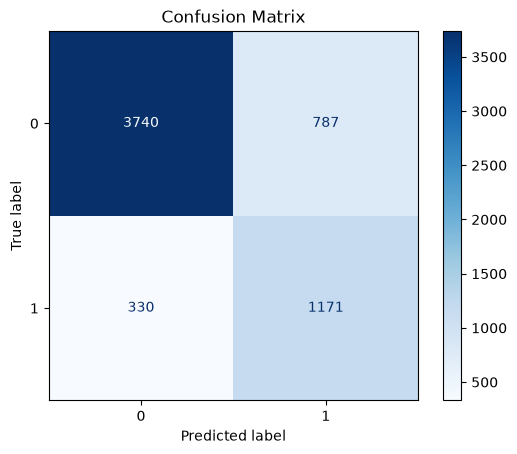

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



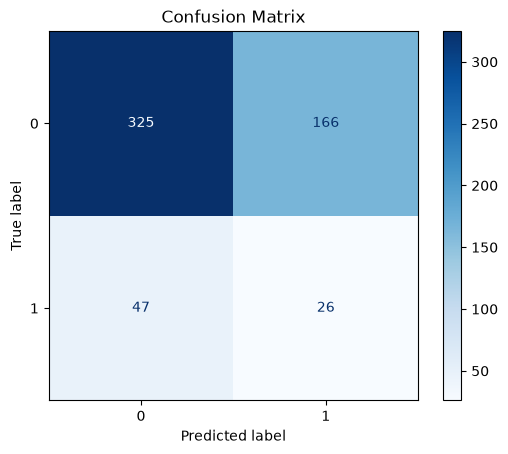

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



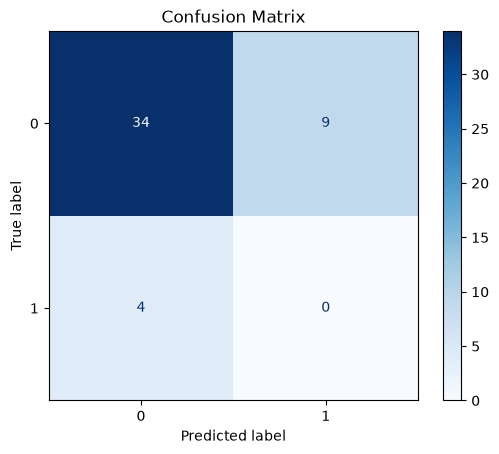

In [51]:
base_tree = tree.DecisionTreeClassifier(max_depth=15, class_weight='balanced')
bagging_clf = bagging_clf = BaggingClassifier(estimator=base_tree, n_estimators=50, max_samples=0.8, bootstrap=True, random_state=42)
bagging_clf.fit(X_train, y_train)
test_model(bagging_clf)
predict_on_subset('race_Black', True, bagging_clf)
predict_on_subset('race_Other', True, bagging_clf)

This led to a significant number of false positives

## Trying to change min_samples_split

              precision    recall  f1-score   support

           0       0.92      0.77      0.83      4527
           1       0.53      0.80      0.64      1501

    accuracy                           0.77      6028
   macro avg       0.72      0.78      0.74      6028
weighted avg       0.82      0.77      0.79      6028



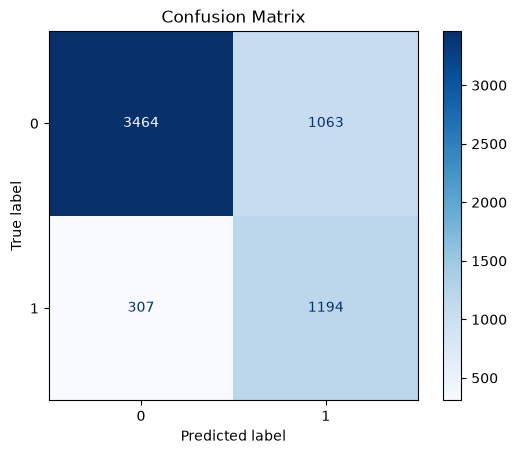

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



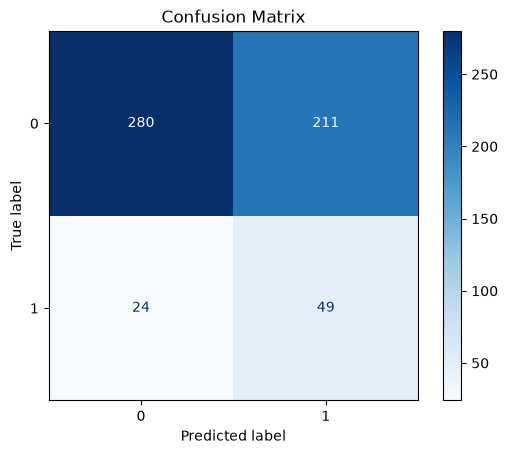

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



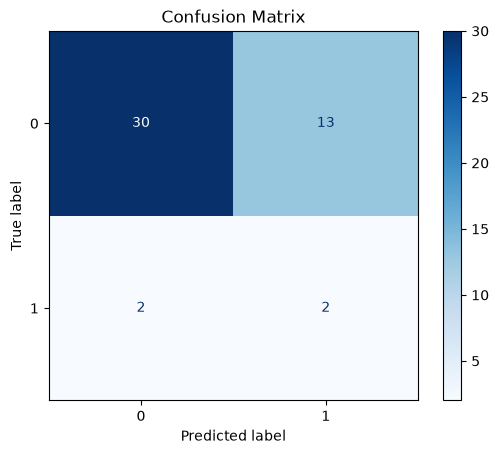

In [52]:
clf = tree.DecisionTreeClassifier(max_depth=15, class_weight='balanced')
clf.fit(X_train, y_train)
test_model(clf)
predict_on_subset('race_Black', True, clf)
predict_on_subset('race_Other', True, clf)

worsens false positives

## Attempting a Stacking Approach

In [53]:
from sklearn.ensemble import StackingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

In [54]:
estimators = [
    ('random_forest', RandomForestClassifier(n_estimators=10, random_state=42)),
    ('decision_tree', DecisionTreeClassifier(max_depth=15, class_weight='balanced', random_state=42))
]
stacking_clf = StackingClassifier(estimators=estimators, final_estimator=LogisticRegression())
stacking_clf.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('random_forest', ...), ('decision_tree', ...)]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegression()
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",None
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",None
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[RandomForestC...ndom_state=42), DecisionTreeC...ndom_state=42)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[objec

              precision    recall  f1-score   support

           0       0.86      0.90      0.88      4527
           1       0.65      0.55      0.59      1501

    accuracy                           0.81      6028
   macro avg       0.75      0.72      0.74      6028
weighted avg       0.80      0.81      0.81      6028



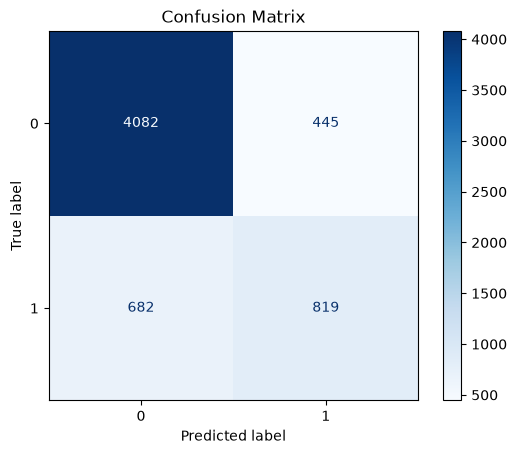

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



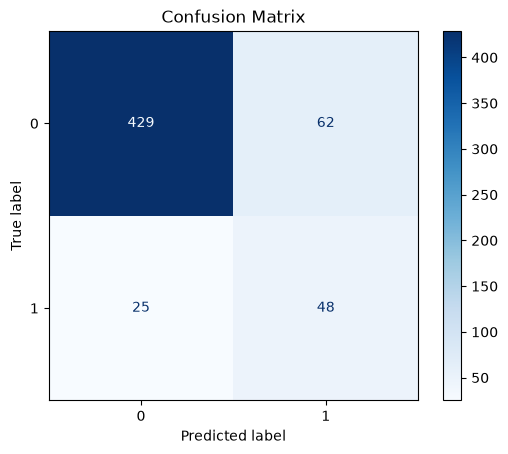

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



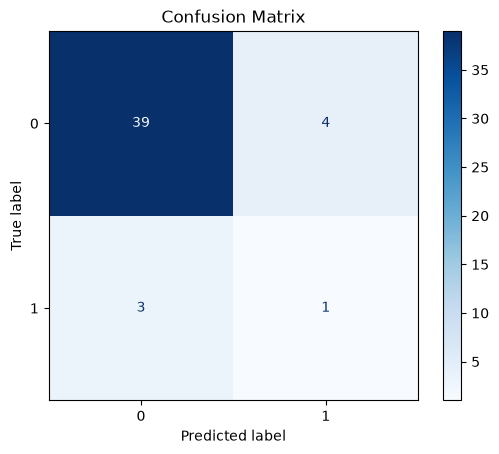

In [55]:
test_model(stacking_clf)
predict_on_subset('race_Black', True, stacking_clf)
predict_on_subset('race_Other', True, stacking_clf)

Using stacking led to a higher f1 score with more false negatives. Interestingly, false positives are now over represented in racial minorities while false negatives are significantly lower. False postives from black individuals make up almost 20% of the false positives even though black individuals only make up around 10% of the data's population

### Trying bagging the stacked algorithm, just because

              precision    recall  f1-score   support

           0       0.87      0.91      0.89      4527
           1       0.68      0.58      0.62      1501

    accuracy                           0.83      6028
   macro avg       0.77      0.74      0.76      6028
weighted avg       0.82      0.83      0.82      6028



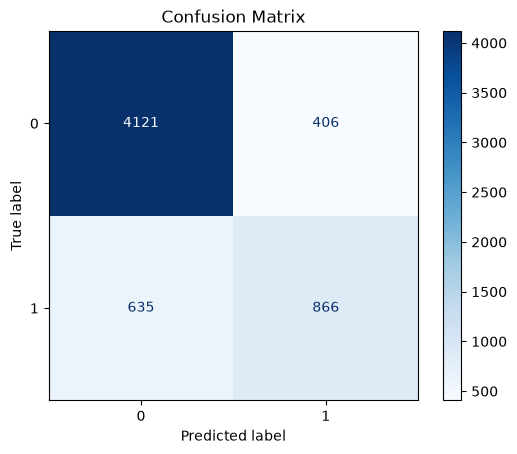

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



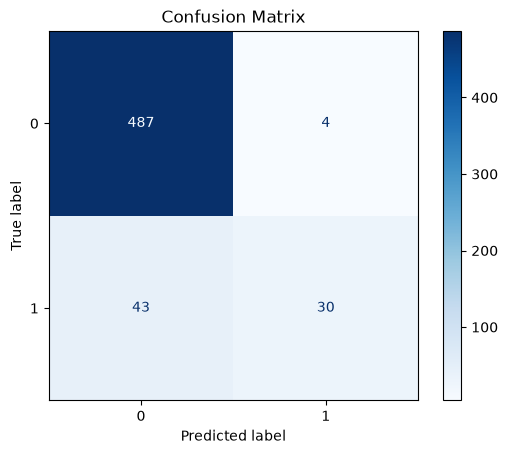

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4527
           1       0.57      0.55      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



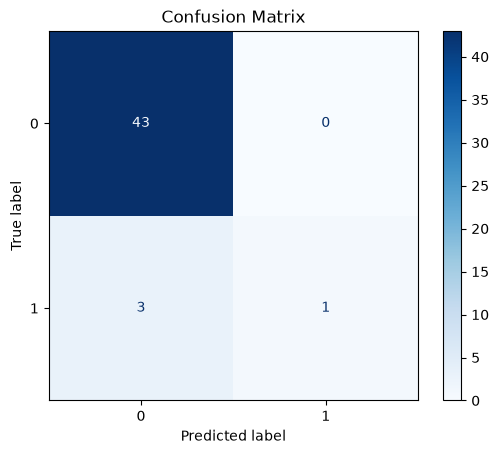

In [56]:
bagging_clf = BaggingClassifier(estimator=stacking_clf, n_estimators=50, max_samples=0.8, bootstrap=True, random_state=42)
bagging_clf.fit(X_train, y_train)
test_model(bagging_clf)
predict_on_subset('race_Black', True, bagging_clf)
predict_on_subset('race_Other', True, bagging_clf)

# Method 2: Logistic Regression with Grid Search



In [57]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, f1_score

# Define the grid search
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100], # regularization constant
    "l1_ratio": [0, 0.5, 1], # l1 ratio
    "class_weight": [None, "balanced"], # penalize according to class unbalance
}

grid = GridSearchCV(
    LogisticRegression(solver="saga", max_iter=1000),
    param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=2,
)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV F1:", round(grid.best_score_, 4))

y_pred = grid.best_estimator_.predict(X_test)
print("Test F1:", round(f1_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred))


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best params: {'C': 0.1, 'class_weight': 'balanced', 'l1_ratio': 1}
Best CV F1: 0.6636
Test F1: 0.6701
              precision    recall  f1-score   support

           0       0.94      0.77      0.85      4527
           1       0.55      0.86      0.67      1501

    accuracy                           0.79      6028
   macro avg       0.75      0.81      0.76      6028
weighted avg       0.84      0.79      0.80      6028



## Evaluate Logistic Regression model

              precision    recall  f1-score   support

           0       0.94      0.77      0.85      4527
           1       0.55      0.86      0.67      1501

    accuracy                           0.79      6028
   macro avg       0.75      0.81      0.76      6028
weighted avg       0.84      0.79      0.80      6028



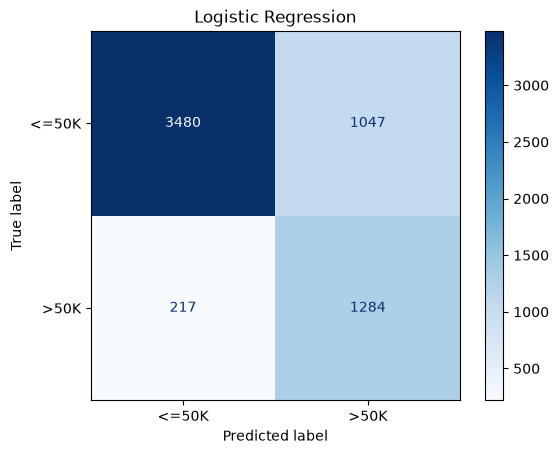

In [58]:
def evaluate_predictions(y_true, y_pred, title="Confusion Matrix"):
    print(classification_report(y_true, y_pred))
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["<=50K", ">50K"])
    disp.plot(cmap=plt.cm.Blues)
    plt.title(title)
    plt.show()


y_pred = grid.best_estimator_.predict(X_test)
evaluate_predictions(y_test, y_pred, "Logistic Regression")

# Method 3: Support Vector Machines

              precision    recall  f1-score   support

           0       0.87      0.93      0.90      4527
           1       0.73      0.57      0.64      1501

    accuracy                           0.84      6028
   macro avg       0.80      0.75      0.77      6028
weighted avg       0.83      0.84      0.83      6028



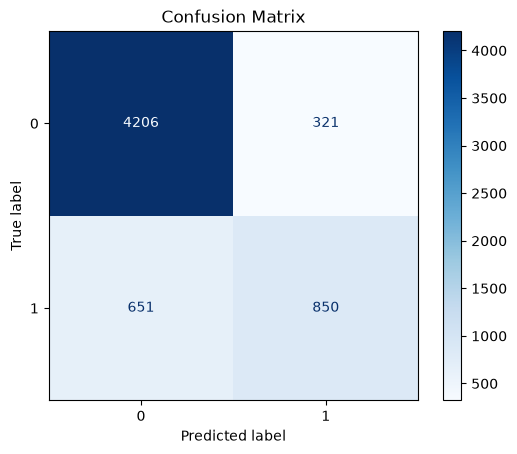

In [59]:
svm_clf = SVC()
svm_clf.fit(X_train, y_train)
test_model(svm_clf)

The default SVM (rbf kernel, C=1) gets 86% accuracy, but it only catches 62% of the people earning more than 50k (recall of 0.62 for class 1). I am going to try other kernels to see if that helps

## Trying different kernels

              precision    recall  f1-score   support

           0       0.86      0.92      0.89      4527
           1       0.70      0.57      0.63      1501

    accuracy                           0.83      6028
   macro avg       0.78      0.74      0.76      6028
weighted avg       0.82      0.83      0.82      6028



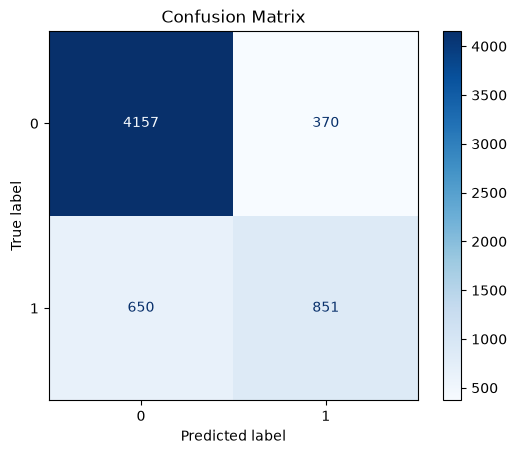

              precision    recall  f1-score   support

           0       0.86      0.93      0.90      4527
           1       0.72      0.56      0.63      1501

    accuracy                           0.84      6028
   macro avg       0.79      0.74      0.76      6028
weighted avg       0.83      0.84      0.83      6028



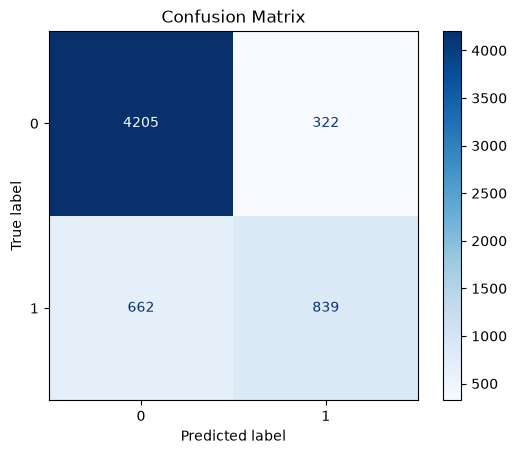

In [60]:
svm_clf = SVC(kernel='linear')
svm_clf.fit(X_train, y_train)
test_model(svm_clf)
svm_clf = SVC(kernel='poly')
svm_clf.fit(X_train, y_train)
test_model(svm_clf)

Neither kernel helped. Linear and polynomial both did slightly worse on the >50k class (F1 of 0.68 compared to 0.69), so I am sticking with rbf

### Trying with class weights balanced

              precision    recall  f1-score   support

           0       0.94      0.77      0.85      4527
           1       0.55      0.85      0.67      1501

    accuracy                           0.79      6028
   macro avg       0.75      0.81      0.76      6028
weighted avg       0.84      0.79      0.80      6028



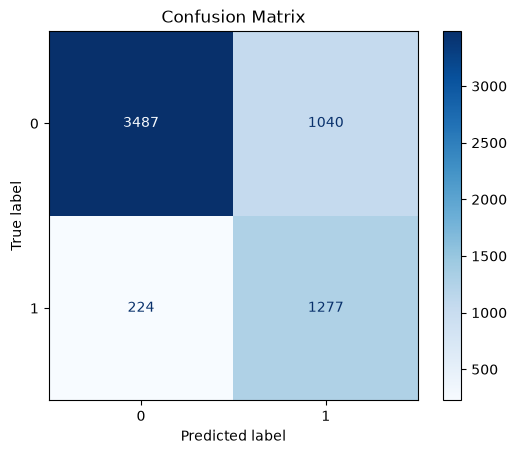

In [61]:
svm_clf = SVC(class_weight='balanced')
svm_clf.fit(X_train, y_train)
test_model(svm_clf)

Balancing the class weights raised the recall for >50k from 0.62 to 0.87, so the model misses far fewer high earners (198 false negatives compared to 575). The tradeoff is a lot more false positives (964 compared to 266) and lower overall accuracy (81% compared to 86%). F1 stayed about the same at 0.69

## Trying different values of C

              precision    recall  f1-score   support

           0       0.94      0.75      0.84      4527
           1       0.53      0.86      0.66      1501

    accuracy                           0.78      6028
   macro avg       0.74      0.81      0.75      6028
weighted avg       0.84      0.78      0.79      6028



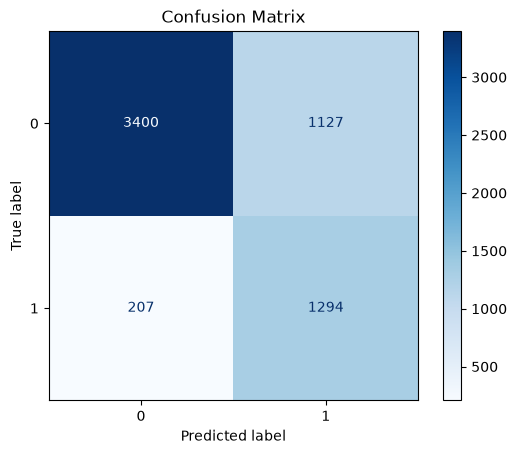

              precision    recall  f1-score   support

           0       0.94      0.77      0.85      4527
           1       0.55      0.85      0.67      1501

    accuracy                           0.79      6028
   macro avg       0.74      0.81      0.76      6028
weighted avg       0.84      0.79      0.80      6028



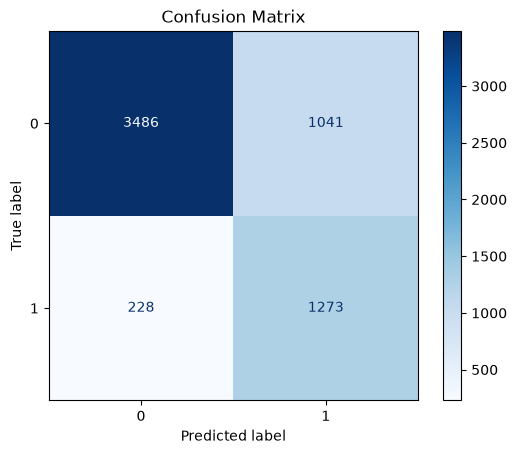

In [62]:
svm_clf = SVC(C=0.1, class_weight='balanced')
svm_clf.fit(X_train, y_train)
test_model(svm_clf)
svm_clf = SVC(C=10, class_weight='balanced')
svm_clf.fit(X_train, y_train)
test_model(svm_clf)

Changing C barely made a difference. C=0.1 dropped accuracy to 80%, and C=10 performed about the same as C=1 while taking longer to train

## Trying different values of gamma

              precision    recall  f1-score   support

           0       0.94      0.73      0.82      4527
           1       0.52      0.87      0.65      1501

    accuracy                           0.76      6028
   macro avg       0.73      0.80      0.74      6028
weighted avg       0.84      0.76      0.78      6028



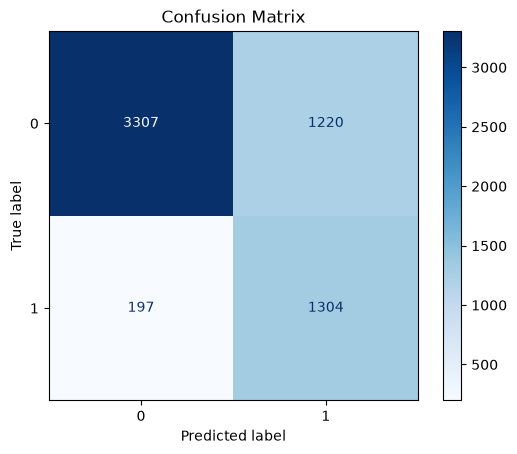

              precision    recall  f1-score   support

           0       0.94      0.77      0.85      4527
           1       0.55      0.85      0.67      1501

    accuracy                           0.79      6028
   macro avg       0.74      0.81      0.76      6028
weighted avg       0.84      0.79      0.80      6028



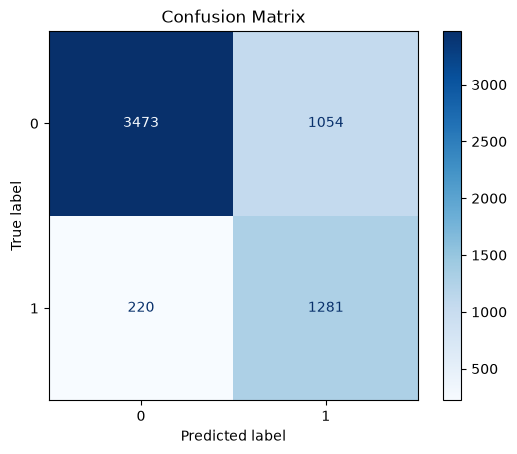

In [63]:
svm_clf = SVC(gamma=0.01, class_weight='balanced')
svm_clf.fit(X_train, y_train)
test_model(svm_clf)
svm_clf = SVC(gamma=0.1, class_weight='balanced')
svm_clf.fit(X_train, y_train)
test_model(svm_clf)

gamma=0.01 was slightly worse. gamma=0.1 gave the exact same results as the default, which makes sense since the default gamma ('scale') works out to roughly 0.1 for this data

## Using Grid Search
To double check the settings I picked by hand, I am running a grid search over the kernel, C and class weights

In [64]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, f1_score

# Define the grid search
param_grid = {
    "C": [0.1, 1, 10], # regularization constant
    "kernel": ["linear", "rbf"], # kernel type
    "class_weight": [None, "balanced"], # penalize according to class unbalance
}

svm_grid = GridSearchCV(
    SVC(),
    param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=2,
)
svm_grid.fit(X_train, y_train)

print("Best params:", svm_grid.best_params_)
print("Best CV F1:", round(svm_grid.best_score_, 4))

y_pred = svm_grid.best_estimator_.predict(X_test)
print("Test F1:", round(f1_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred))


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best params: {'C': 1, 'class_weight': 'balanced', 'kernel': 'rbf'}
Best CV F1: 0.6655
Test F1: 0.6689
              precision    recall  f1-score   support

           0       0.94      0.77      0.85      4527
           1       0.55      0.85      0.67      1501

    accuracy                           0.79      6028
   macro avg       0.75      0.81      0.76      6028
weighted avg       0.84      0.79      0.80      6028



## Evaluate SVM model

              precision    recall  f1-score   support

           0       0.94      0.77      0.85      4527
           1       0.55      0.85      0.67      1501

    accuracy                           0.79      6028
   macro avg       0.75      0.81      0.76      6028
weighted avg       0.84      0.79      0.80      6028



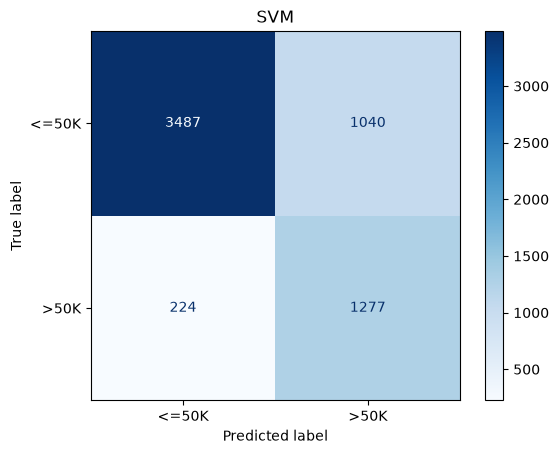

In [65]:
y_pred = svm_grid.best_estimator_.predict(X_test)
evaluate_predictions(y_test, y_pred, "SVM")

The grid search agreed with what I found by hand: the rbf kernel with C=1 and balanced class weights gave the best F1 (0.69 on the test set). It catches 87% of high earners, but only 57% of the people it flags as earning more than 50k actually do